In [1]:
import numpy as np
import pandas as pd

import warnings
warnings.filterwarnings('ignore')

In [4]:
from sklearn.datasets import fetch_california_housing

In [6]:
cali=fetch_california_housing()

In [7]:
X=cali['data']

In [8]:
X.shape

(20640, 8)

In [9]:
X.mean()

172.9556735813799

In [11]:
#Step 1
mu=X.mean(axis=0)
#mean centering
X_=(X-mu)
X_.shape

(20640, 8)

In [12]:
#Step 2-Covariance Matrix
S=np.dot(X_.T,X_)
S.shape

(8, 8)

In [15]:
#Step 3-EigenValue Decomposition
lambdas,vectors =np.linalg.eig(S)


In [16]:
lambdas.shape

(8,)

In [17]:
lambdas[:2] #Top 2 Eigen Values

array([2.64692082e+10, 2.99909311e+06])

In [18]:
vectors.shape

(8, 8)

In [21]:
#STEP 4-TO GET TOP K
vectors[:1] #First(Its SECOND ONE BCUZ FIRST ONE IS EMPTY) Eigen Vector

array([[-8.11734515e-06, -1.98005360e-02, -6.72539368e-03,
         3.25026318e-02, -4.18810230e-01, -8.94886858e-01,
         1.03266610e-01,  1.07785880e-01]])

In [22]:
V=vectors[:,:2]
V.shape

(8, 2)

In [24]:
#LAST STEP PROJECTION
X_.shape

(20640, 8)

In [25]:
V.shape

(8, 2)

In [26]:
X_new=np.dot(X_,V)
X_new.shape

(20640, 2)

In [27]:
X_new[:5]

array([[1103.51264821,    8.56663624],
       [-975.54124442,   -4.67041774],
       [ 929.54990812,   20.03465092],
       [ 867.55004804,   20.33144138],
       [ 860.55041068,   20.32882664]])

In [33]:
total=sum(lambdas)

In [37]:
explained_variance=np.round(lambdas/total,4)
explained_variance

array([9.998e-01, 1.000e-04, 1.000e-04, 0.000e+00, 0.000e+00, 0.000e+00,
       0.000e+00, 0.000e+00])

In [38]:
explained_variance[:2].sum()

0.9999

In [41]:
cummulative_variance=np.cumsum(explained_variance)
cummulative_variance

array([0.9998, 0.9999, 1.    , 1.    , 1.    , 1.    , 1.    , 1.    ])

In [42]:
import matplotlib.pyplot as plt

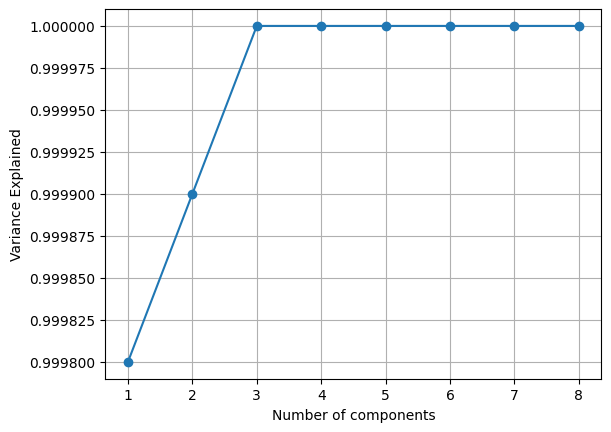

In [49]:
plt.plot(range(1,len(cummulative_variance)+1),cummulative_variance,marker='o')
plt.xlabel('Number of components')
plt.ylabel('Variance Explained')
plt.grid('on')
plt.show()

In [28]:
#SKLEARN
from sklearn.decomposition import PCA

In [29]:
pca=PCA(n_components=2)

In [30]:
pca.fit_transform(X)

array([[-1103.51264821,     8.56663624],
       [  975.54124442,    -4.67041774],
       [ -929.54990812,    20.03465092],
       ...,
       [ -418.43757543,   -12.90825582],
       [ -684.43952537,   -12.79458051],
       [  -38.43624736,   -12.67037806]])

In [31]:
pca.explained_variance_

array([1.28248501e+06, 1.45311939e+02])

In [32]:
pca.explained_variance_ratio_

array([9.99789327e-01, 1.13281110e-04])

In [39]:
pca.explained_variance_ratio_.sum()

0.9999026078862243